# Cleaning and Analysis

**Question:** *What makes a mortgage cost more?*

This notebook starts from the file prepared in notebook 01 (1,727,644 applications, 15 columns) 
1. Shows what happened to each application
2. Keeps approved loans
3. Checks data quality
4. Cleans the data
5. Creates features for the analysis and the app
6. Checks the distribution of prices
7. Answers Question 1: does a smaller down payment cost more?
8. Answers Question 2: do closing costs differ across states?

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

year = 2025
states_chosen = ["CA", "MA", "FL", "TX", "MI", "OH"]
state_tiers = {"CA": "Expensive", "MA": "Expensive", "FL": "Mid",
               "TX": "Mid", "MI": "Low", "OH": "Low"}

# Folders: full path to the project folder
PROJECT_DIR = Path(r"C:\Users\havil\CMSE_midterm_HMDA_project")
INTERIM_DIR = PROJECT_DIR / "data" / "interim"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Load the file saved by notebook 01
final_df = pd.read_parquet(INTERIM_DIR / f"hmda_{year}_purchase_filtered.parquet", dtype_backend="pyarrow")
print(f"Loaded {len(final_df):,} rows x {final_df.shape[1]} columns")

Loaded 1,727,644 rows x 15 columns


## Step 1 · How does my data look?
A first look at the rows, size and column types.

In [2]:
final_df.head()

,state_code,action_taken,loan_type,interest_rate,rate_spread,total_loan_costs,loan_amount,loan_to_value_ratio,property_value,income,debt_to_income_ratio,loan_term,intro_rate_period,interest_only_payment,balloon_payment
0,CA,6,2,3.125,NA,0.01,305000.0,NA,355000,NA,NA,360,NA,2,2
1,CA,8,1,6.875,0.734,NA,1005000.0,77,1305000,250,44,360,NA,2,2
2,CA,6,1,6.375,NA,15210.50,2645000.0,NA,3305000,948,NA,360,84,2,2
3,CA,6,1,5.25,NA,17017.23,845000.0,NA,985000,145,NA,360,NA,2,2
4,CA,6,1,5.75,NA,7256.00,1435000.0,NA,3065000,568,NA,360,NA,2,2


In [3]:
final_df.shape

(1727644, 15)

In [4]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1727644 entries, 0 to 1727643
Data columns (total 15 columns):
 #   Column                 Dtype          
---  ------                 -----          
 0   state_code             string[pyarrow]
 1   action_taken           string[pyarrow]
 2   loan_type              string[pyarrow]
 3   interest_rate          string[pyarrow]
 4   rate_spread            string[pyarrow]
 5   total_loan_costs       string[pyarrow]
 6   loan_amount            string[pyarrow]
 7   loan_to_value_ratio    string[pyarrow]
 8   property_value         string[pyarrow]
 9   income                 string[pyarrow]
 10  debt_to_income_ratio   string[pyarrow]
 11  loan_term              string[pyarrow]
 12  intro_rate_period      string[pyarrow]
 13  interest_only_payment  string[pyarrow]
 14  balloon_payment        string[pyarrow]
dtypes: string[pyarrow](15)
memory usage: 177.4 MB


The info tab shows that all columns are string[pyarroow], because notebook 1 reads everything as text to keep HMDA codes like "NA" and "Exempt". In step-4 the columns are again changes based to integers and floats.

## Step 2 · Keep approved loans only
action_taken column shows what happened to each application. 
Code-1  means the loan was originated. Only those loans have a price, so I kept only those. 
Denied and withdrawn applications have no price, so there is nothing to fill in.

In [5]:
outcome_names = {"1": "Originated", "2": "Approved, not accepted", "3": "Denied",
                 "4": "Withdrawn", "5": "Incomplete", "6": "Purchased loan",
                 "7": "Preapproval denied", "8": "Preapproval approved, not accepted"}

(final_df["action_taken"].astype(str).map(outcome_names).value_counts(normalize=True) * 100).round(1)

action_taken
Originated                            55.4
Purchased loan                        20.6
Withdrawn                             13.1
Denied                                 6.2
Approved, not accepted                 1.6
Incomplete                             1.4
Preapproval approved, not accepted     1.4
Preapproval denied                     0.2
Name: proportion, dtype: float64

In [6]:
df = final_df[final_df["action_taken"] == "1"].reset_index(drop=True)
df.shape

(956768, 15)

In [7]:
df["state_code"].value_counts()

state_code
TX    288274
FL    224328
CA    205033
OH    106798
MI     85045
MA     47290
Name: count, dtype: int64[pyarrow]

## Step 3 · Missing values
HMDA does not leave cells empty. It writes "NA" when a field doesn't apply and "Exempt" when a small lender didn't report it. 
I counted both before changing the data types, because after that they both become NaN.

In [8]:
missing = pd.DataFrame({
    "NA": (df == "NA").sum(),
    "Exempt": (df == "Exempt").sum(),
})
missing["NA %"] = (missing["NA"] / len(df) * 100).round(2)
missing

,NA,Exempt,NA %
state_code,0,0,0.00
action_taken,0,0,0.00
loan_type,0,0,0.00
interest_rate,328,3,0.03
rate_spread,6876,4,0.72
total_loan_costs,15439,5,1.61
loan_amount,0,0,0.00
loan_to_value_ratio,26063,3,2.72
property_value,6075,3,0.63
income,8621,0,0.90


Based on the above result very few values are missing: under 3% for every price and loan column, with loan-to-value the highest at 2.7%. 
intro_rate_period is “NA” for 92% of loans, but that means the loan is fixed-rate, not that the data is missing.

## Step 4 · Change data types
I changed the columns that have amounts to numbers. Anything that is not a number ("NA", "Exempt") becomes NaN.

Columns that have codes (state, loan type, debt-to-income range, intro rate period, interest-only, balloon) stay as text.

In [9]:
number_cols = ["interest_rate", "rate_spread", "total_loan_costs", "loan_amount",
               "loan_to_value_ratio", "property_value", "income", "loan_term"]

for col in number_cols:
    df[col] = pd.to_numeric(df[col].astype(str), errors="coerce")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 956768 entries, 0 to 956767
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype          
---  ------                 --------------   -----          
 0   state_code             956768 non-null  string[pyarrow]
 1   action_taken           956768 non-null  string[pyarrow]
 2   loan_type              956768 non-null  string[pyarrow]
 3   interest_rate          956437 non-null  float64        
 4   rate_spread            949888 non-null  float64        
 5   total_loan_costs       941324 non-null  float64        
 6   loan_amount            956768 non-null  float64        
 7   loan_to_value_ratio    930702 non-null  float64        
 8   property_value         950690 non-null  float64        
 9   income                 948147 non-null  float64        
 10  debt_to_income_ratio   956768 non-null  string[pyarrow]
 11  loan_term              955700 non-null  float64        
 12  intro_rate_period      956768 

In [10]:
df.isnull().sum()

state_code                   0
action_taken                 0
loan_type                    0
interest_rate              331
rate_spread               6880
total_loan_costs         15444
loan_amount                  0
loan_to_value_ratio      26066
property_value            6078
income                    8621
debt_to_income_ratio         0
loan_term                 1068
intro_rate_period            0
interest_only_payment        0
balloon_payment              0
dtype: int64

## Step 5 · Summary statistics
Using .describe() for summary stats.

In [11]:
df[number_cols].describe().round(2)

,interest_rate,rate_spread,total_loan_costs,loan_amount,loan_to_value_ratio,property_value,income,loan_term
count,956437.00,949888.00,941324.00,956768.00,930702.00,950690.00,948147.00,955700.00
mean,6.27,0.07,9220.53,445424.35,84.91,560997.75,179.87,354.18
std,0.84,0.93,6579.78,403153.83,16.58,609463.71,462.34,32.72
min,0.00,-414.00,0.00,5000.00,1.93,5000.00,-3194.00,1.00
25%,5.88,-0.28,4901.14,255000.00,80.00,285000.00,83.00,360.00
50%,6.38,0.12,7630.82,355000.00,90.00,405000.00,124.00,360.00
75%,6.75,0.52,11858.92,525000.00,96.50,635000.00,191.00,360.00
max,20.00,31.50,438313.00,63105000.00,502.67,95005000.00,114299.00,720.00


In [12]:
print("Interest rate under 0.5% or over 15%:", ((df["interest_rate"] < 0.5) | (df["interest_rate"] > 15)).sum())
print("Loan-to-value under 1% or over 150%:", ((df["loan_to_value_ratio"] < 1) | (df["loan_to_value_ratio"] > 150)).sum())
print("Rate spread under -5 or over 10:", ((df["rate_spread"] < -5) | (df["rate_spread"] > 10)).sum())

Interest rate under 0.5% or over 15%: 304
Loan-to-value under 1% or over 150%: 37
Rate spread under -5 or over 10: 899


In [13]:
df["loan_term"].value_counts().head()

loan_term
360.0    911239
180.0     20246
240.0      6297
372.0      4286
300.0      3337
Name: count, dtype: int64

In [14]:
(df["intro_rate_period"] == "NA").value_counts()   # True = fixed rate

intro_rate_period
True     877422
False     79346
Name: count, dtype: int64[pyarrow]

## Step 6 · Clean the data
To compare prices fairly, I keep only one kind of loan and remove impossible values:
- 30-year loans (360 months), the most common term
- Fixed rate, because adjustable-rate loans are priced differently
- No interest-only or balloon payments, because these are unusual loans
- Valid values: interest rate 0.5–15%, loan-to-value 1–150%, rate spread −5 to 10

Extreme but possible values are kept, because I use medians, which they don't distort.

In [15]:
counts = [("Approved loans", len(df))]

df = df[df["loan_term"] == 360]
counts.append(("30-year term", len(df)))

df = df[df["intro_rate_period"] == "NA"]
counts.append(("Fixed rate", len(df)))

df = df[df["interest_only_payment"] != "1"]
counts.append(("Not interest-only", len(df)))

df = df[df["balloon_payment"] != "1"]
counts.append(("No balloon payment", len(df)))

df = df[df["interest_rate"].between(0.5, 15)]
counts.append(("Valid interest rate", len(df)))

df = df[df["loan_to_value_ratio"].between(1, 150)]
counts.append(("Valid loan-to-value", len(df)))

# keep loans with a valid rate spread, or no rate spread reported
df = df[df["rate_spread"].between(-5, 10) | df["rate_spread"].isna()]
counts.append(("Valid rate spread", len(df)))

clean_funnel = pd.DataFrame(counts, columns=["step", "rows_remaining"])
clean_funnel["removed"] = clean_funnel["rows_remaining"].diff().fillna(0).abs().astype(int)
clean_funnel

,step,rows_remaining,removed
0,Approved loans,956768,0
1,30-year term,911239,45529
2,Fixed rate,836428,74811
3,Not interest-only,834944,1484
4,No balloon payment,834839,105
5,Valid interest rate,834352,487
6,Valid loan-to-value,810854,23498
7,Valid rate spread,810670,184


In [16]:
# Save the table for the app's Data & preparation tab
clean_funnel.to_csv(PROJECT_DIR / "data" / "funnel_cleaning.csv", index=False)

## Step 7 · Create new columns and save
| New column | How it's made |
|---|---|
| `loan_type_label` | Loan type code as a word: Conventional, FHA, VA, USDA |
| `tier` | The state's home-price tier: Expensive, Mid, Low |
| `down_payment_band` | Down-payment group from loan-to-value (80% loan-to-value = 20% down) |
| `loan_costs_pct` | Closing costs as a % of the loan |

The down-payment groups follow mortgage rules: below 20% down usually needs mortgage insurance, and 3% is the lowest conventional down payment.

In [17]:
df["loan_type_label"] = df["loan_type"].astype(str).map({"1": "Conventional", "2": "FHA", "3": "VA", "4": "USDA"})
df["tier"] = df["state_code"].astype(str).map(state_tiers)

df["down_payment_band"] = pd.cut(df["loan_to_value_ratio"],
                                 bins=[0, 80, 90, 95, 97, 150],
                                 labels=["20%+ down", "10-20% down", "5-10% down", "3-5% down", "Under 3% down"])

df["loan_costs_pct"] = df["total_loan_costs"] / df["loan_amount"] * 100

df["down_payment_band"].value_counts(sort=False)

down_payment_band
20%+ down        278590
10-20% down      101509
5-10% down       115398
3-5% down        191785
Under 3% down    123388
Name: count, dtype: int64

In [18]:
app_cols = ["state_code", "tier", "loan_type_label", "interest_rate", "rate_spread",
            "total_loan_costs", "loan_costs_pct", "loan_amount", "loan_to_value_ratio",
            "down_payment_band", "income"]

clean = df[app_cols].reset_index(drop=True)
clean.to_parquet(PROCESSED_DIR / f"hmda_{year}_pricing_clean.parquet", index=False)
clean.shape

(810670, 11)

## Step 8 · Correlation
I am using Spearman correlation because prices are skewed and it is less affected by extreme values.

In [19]:
corr_cols = ["interest_rate", "rate_spread", "total_loan_costs", "loan_costs_pct",
             "loan_amount", "loan_to_value_ratio", "income"]

corr = clean[corr_cols].corr(method="spearman").round(2)
corr

,interest_rate,rate_spread,total_loan_costs,loan_costs_pct,loan_amount,loan_to_value_ratio,income
interest_rate,1.00,0.77,-0.12,-0.13,0.01,-0.13,0.15
rate_spread,0.77,1.00,0.14,0.22,-0.10,0.13,-0.01
total_loan_costs,-0.12,0.14,1.00,0.63,0.37,0.20,0.20
loan_costs_pct,-0.13,0.22,0.63,1.00,-0.42,0.27,-0.39
loan_amount,0.01,-0.10,0.37,-0.42,1.00,-0.10,0.74
loan_to_value_ratio,-0.13,0.13,0.20,0.27,-0.10,1.00,-0.24
income,0.15,-0.01,0.20,-0.39,0.74,-0.24,1.00


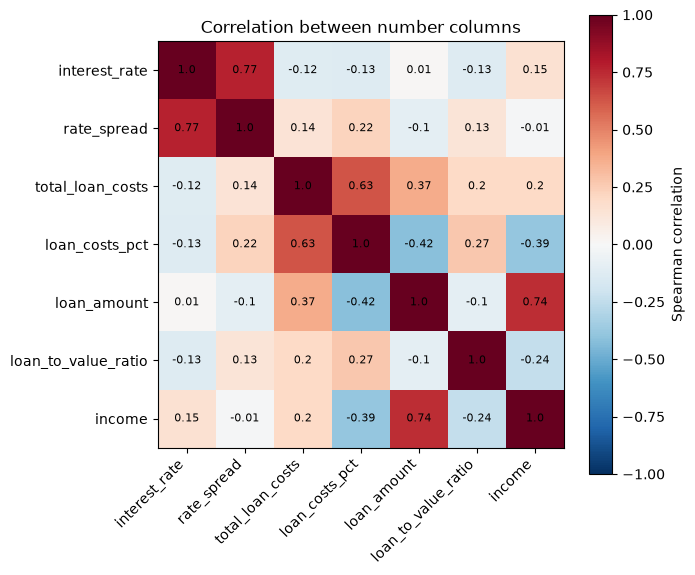

In [20]:
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)))
ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, corr.iloc[i, j], ha="center", va="center", fontsize=8)
fig.colorbar(image, label="Spearman correlation")
ax.set_title("Correlation between number columns")
plt.tight_layout()
plt.show()

The plot shows three strong pairs: interest rate goes up with rate spread (0.77), people with higher incomes borrow more (0.74), and loans with higher closing costs also have a higher cost percentage (0.63). Down payment and price are only weakly linked overall (0.13) because different loan types behave differently, so Question 1 looks at each loan type on its own.

## Step 9 · Distributions
I checked the shape of the two prices. If the data is skewed, the mean is pulled away from the typical value, so the median is a better summary.

In [21]:
spread = clean["rate_spread"].dropna()
costs = clean["total_loan_costs"].dropna()

print("Rate spread:      mean =", round(spread.mean(), 2), "| median =", round(spread.median(), 2))
print("Total loan costs: mean =", round(costs.mean()), "| median =", round(costs.median()))

Rate spread:      mean = 0.08 | median = 0.15
Total loan costs: mean = 9426 | median = 7894


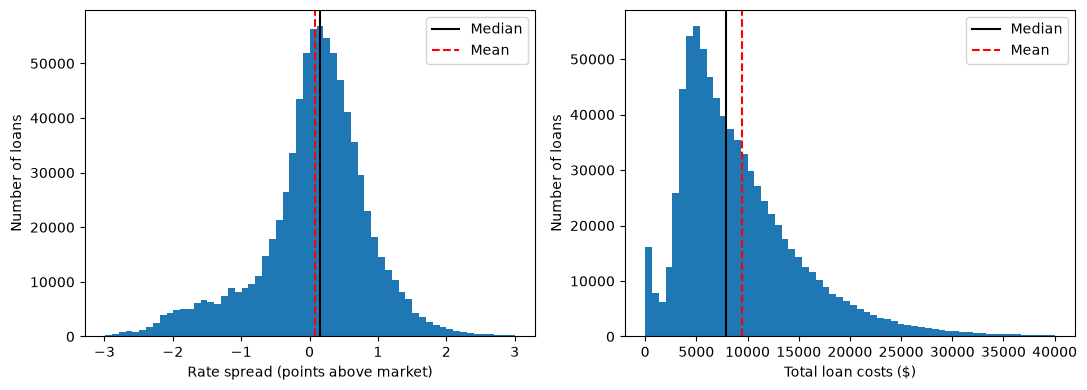

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(spread[spread.between(-3, 3)], bins=60)
axes[0].axvline(spread.median(), color="black", label="Median")
axes[0].axvline(spread.mean(), color="red", linestyle="--", label="Mean")
axes[0].set_xlabel("Rate spread (points above market)")
axes[0].set_ylabel("Number of loans")
axes[0].legend()

axes[1].hist(costs[costs.between(0, 40000)], bins=60)
axes[1].axvline(costs.median(), color="black", label="Median")
axes[1].axvline(costs.mean(), color="red", linestyle="--", label="Mean")
axes[1].set_xlabel("Total loan costs ($)")
axes[1].set_ylabel("Number of loans")
axes[1].legend()

plt.tight_layout()
plt.show()

Most loans are priced close to the market rate, with a few priced well below it. Closing costs have a long tail of expensive loans that pulls the mean above the median, the data is skewed. so I use medians.

## Step 10 · Question 1: Does a smaller down payment mean a higher price?
I compared the median rate spread for each down-payment group, separately for Conventional, FHA and VA loans. USDA is left out because it has few loans.

In [23]:
q1 = clean[clean["loan_type_label"].isin(["Conventional", "FHA", "VA"])]

q1_medians = q1.pivot_table(index="down_payment_band", columns="loan_type_label",
                            values="rate_spread", aggfunc="median", observed=True)
q1_medians.round(2)

loan_type_label,Conventional,FHA,VA
down_payment_band,,,
20%+ down,0.03,0.24,-0.54
10-20% down,0.23,0.14,-0.53
5-10% down,0.39,0.21,-0.51
3-5% down,0.45,0.27,-0.51
Under 3% down,0.40,0.95,-0.46


In [24]:
q1_counts = q1.pivot_table(index="down_payment_band", columns="loan_type_label",
                           values="rate_spread", aggfunc="count", observed=True)
q1_counts

loan_type_label,Conventional,FHA,VA
down_payment_band,,,
20%+ down,262243,7207,8160
10-20% down,81604,13528,5831
5-10% down,94121,16041,4462
3-5% down,40726,148708,1195
Under 3% down,17442,37811,63658


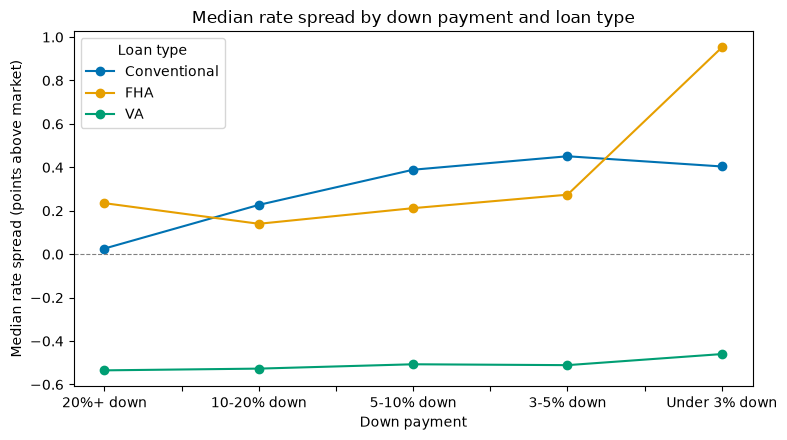

In [25]:
q1_medians = q1_medians.where(q1_counts >= 100)   # hide groups with fewer than 100 loans

ax = q1_medians.plot(marker="o", figsize=(8, 4.5), color=["#0072B2", "#E69F00", "#009E73"])
ax.axhline(0, color="grey", linestyle="--", linewidth=0.8)   # 0 = priced at the market rate
ax.set_xlabel("Down payment")
ax.set_ylabel("Median rate spread (points above market)")
ax.set_title("Median rate spread by down payment and loan type")
ax.legend(title="Loan type")
plt.tight_layout()
plt.show()

Based ont he plot, for conventional loans, the price goes up as the down payment gets smaller, and FHA stays fairly flat until it jumps sharply below 3% down. VA loans stay below the market rate at every down payment.

## Step 11 · Question 2: Do closing costs differ across states?
I compare median closing costs by state, in dollars and as a % of the loan. States are ordered from expensive to low home prices. Costs above 20% of the loan are removed as likely errors.

In [26]:
q2 = clean.dropna(subset=["total_loan_costs"])
q2 = q2[q2["loan_costs_pct"] <= 20]

q2_summary = q2.groupby("state_code").agg(
    loans=("total_loan_costs", "count"),
    median_cost=("total_loan_costs", "median"),
    median_cost_pct=("loan_costs_pct", "median"),
    median_loan=("loan_amount", "median"),
)
q2_summary = q2_summary.loc[states_chosen].round(2)
q2_summary

,loans,median_cost,median_cost_pct,median_loan
state_code,,,,
CA,161724,10022.86,2.01,545000.0
MA,36961,5632.10,1.29,485000.0
FL,192835,8954.81,2.80,345000.0
TX,248039,8590.49,2.92,305000.0
MI,69162,4521.80,2.11,235000.0
OH,88256,5349.35,2.52,235000.0


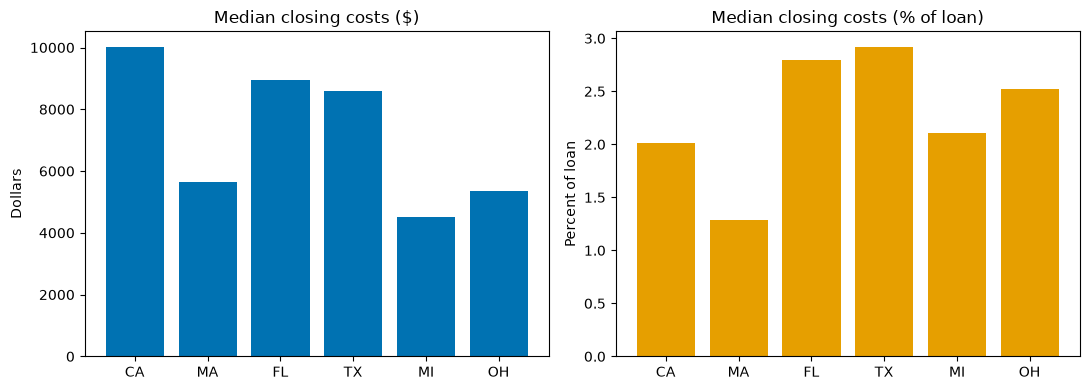

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(states_chosen, q2_summary["median_cost"], color="#0072B2")
axes[0].set_title("Median closing costs ($)")
axes[0].set_ylabel("Dollars")

axes[1].bar(states_chosen, q2_summary["median_cost_pct"], color="#E69F00")
axes[1].set_title("Median closing costs (% of loan)")
axes[1].set_ylabel("Percent of loan")

plt.tight_layout()
plt.show()

## Summary

In [28]:
print("Applications from notebook 1:", f"{len(final_df):,}")
print("Approved loans:              ", f"{clean_funnel['rows_remaining'].iloc[0]:,}")
print("Clean loans for the app:     ", f"{len(clean):,}")

Applications from notebook 1: 1,727,644
Approved loans:               956,768
Clean loans for the app:      810,670


**Decisions:**
- Kept approved loans only; denied applications have no price, so nothing was filled in.
- Kept 30-year fixed-rate loans only, so loans compare fairly.
- Removed impossible values and kept extreme but possible ones.
- Used medians because prices are skewed.

**Findings:**
- **Down payment:** for conventional loans, the price rises as the down payment gets smaller. FHA stays fairly flat until it jumps below 3% down, and VA loans stay below the market rate at every down payment.
- **Closing costs:** California pays the most in dollars, but Texas and Florida pay the most as a share of the loan, and Massachusetts the least. So closing costs don't simply follow home prices.
    
**Output:** data/processed/hmda_2025_pricing_clean.parquet, used by the Streamlit app.